In [1]:
import pandas as pd
import numpy as np
import time

# --- PARÁMETROS DE EJECUCIÓN ---

# El producto que queremos analizar
PRODUCTO_A_ANALIZAR = 'Strawberries'

# Parámetros del MDP
GAMMA = 0.95  # Factor de descuento
THETA = 0.0001 # Umbral de convergencia

print(f"--- Iniciando Proceso MDP para: {PRODUCTO_A_ANALIZAR} ---")

# --- PASO 1: Cargar y Limpiar los Datos ---

print("\n--- PASO 1: Cargando y Limpiando Datos ---")
try:
    df_raw = pd.read_csv("ProductPriceIndex.csv")
except FileNotFoundError:
    print("¡ERROR! No se encontró 'ProductPriceIndex.csv'.")
    print("Por favor, súbelo al panel izquierdo de Colab y vuelve a ejecutar.")
    # Detener la ejecución si no se encuentra el archivo
    raise

# Copiamos para evitar SettingWithCopyWarning
df_clean = df_raw.copy()

# Definimos las columnas de precios
price_cols = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']

# Quitamos el símbolo '$' y convertimos a número (float)
for col in price_cols:
    df_clean[col] = df_clean[col].astype(str).str.replace('$', '', regex=False)
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Convertimos la columna 'date' a formato datetime
df_clean['date'] = pd.to_datetime(df_clean['date'])

# Filtramos solo por el producto seleccionado
df_product = df_clean[df_clean['productname'] == PRODUCTO_A_ANALIZAR].copy()

# Reemplazamos 0 por NaN (no podemos vender a 0)
df_product = df_product.replace(0, np.nan)

# Eliminamos cualquier fila (semana) que tenga un precio faltante (NaN)
rows_before = len(df_product)
df_product = df_product.dropna(subset=price_cols)
rows_after = len(df_product)
print(f"Filas eliminadas por datos faltantes/cero: {rows_before - rows_after}")

# Ordenar por fecha (¡crucial!)
df_product = df_product.sort_values(by='date').reset_index(drop=True)
print(f"Datos limpios listos para '{PRODUCTO_A_ANALIZAR}'. Total de semanas: {len(df_product)}")

# --- PASO 2: Discretizar y Definir Estados (S) ---

print("\n--- PASO 2: Definiendo Estados (S) ---")
cat_cols = ['farm_cat', 'atl_cat', 'chi_cat', 'la_cat', 'ny_cat']
df_states = df_product.copy()

# Discretizar usando 3 cuantiles (Bajo=0, Medio=1, Alto=2)
for i, col in enumerate(price_cols):
    cat_col_name = cat_cols[i]
    df_states[cat_col_name] = pd.qcut(df_states[col], q=3, labels=[0, 1, 2], duplicates='drop')
    df_states[cat_col_name] = df_states[cat_col_name].astype(int)

# Definir el Estado 's' como un string (ej. "0-1-2-1-0")
str_cat_cols = [col + "_str" for col in cat_cols]
for i, col in enumerate(cat_cols):
    df_states[str_cat_cols[i]] = df_states[col].astype(str)
df_states['state'] = df_states[str_cat_cols].agg('-'.join, axis=1)

STATES = sorted(df_states['state'].unique())
print(f"Total de estados (S) únicos encontrados: {len(STATES)} (de 243 teóricos)")

# --- PASO 3: Construir Recompensas (R) y Transiciones (P) ---

print("\n--- PASO 3: Construyendo Modelos R y P ---")

# --- 3a. Construir Recompensa R(s, a) ---
actions = ['atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']
reward_cols = ['R_atl', 'R_chi', 'R_la', 'R_ny']
ACTION_NAMES = {
    'R_atl': 'Vender en Atlanta',
    'R_chi': 'Vender en Chicago',
    'R_la': 'Vender en Los Angeles',
    'R_ny': 'Vender en Nueva York'
}

# Calculamos la ganancia (Recompensa) para cada acción
for i, action_col in enumerate(actions):
    df_states[reward_cols[i]] = df_states[action_col] - df_states['farmprice']

# Agrupamos por 'state' y calculamos la media de las ganancias
R_table = df_states.groupby('state')[reward_cols].mean()
R_dict = R_table.to_dict('index')
print("Tabla de Recompensas R(s, a) construida.")

# --- 3b. Construir Transición P(s' | s) ---
df_states['next_state'] = df_states['state'].shift(-1)
df_transitions = df_states.dropna(subset=['next_state'])

# Contamos transiciones (s, s')
transition_counts = df_transitions.groupby(['state', 'next_state']).size().to_frame(name='count')
# Contamos visitas totales (s)
state_counts_total = df_transitions.groupby('state').size().to_frame(name='total_s_visits')

# Calculamos P(s' | s) = count(s -> s') / total_visits(s)
P_table_full = transition_counts.join(state_counts_total, on='state')
P_table_full['prob'] = P_table_full['count'] / P_table_full['total_s_visits']

# Convertir P a un diccionario anidado para velocidad
P_dict = {}
for s in STATES:
    P_dict[s] = {} # Asegura que cada estado tenga una entrada
for _, row in P_table_full.iterrows():
    # Asegurarnos de que el estado de 'state' existe
    if row.name[0] not in P_dict:
        P_dict[row.name[0]] = {}
    P_dict[row.name[0]][row.name[1]] = row['prob']

print("Tabla de Transiciones P(s' | s) construida.")

# --- PASO 4: Resolver el MDP (Iteración de Valor) ---

print("\n--- PASO 4: Resolviendo el MDP con Iteración de Valor ---")
start_time = time.time()

# V(s) - El "Valor" de estar en un estado 's'
V = {s: 0 for s in STATES}

iteration = 0
while True:
    iteration += 1
    delta = 0
    V_new = V.copy()

    for s in STATES:
        q_sa = {}
        for a_col in reward_cols: # 'R_atl', 'R_chi', ...

            # 1. Recompensa inmediata R(s, a)
            reward = R_dict.get(s, {}).get(a_col, 0) # Usar .get para seguridad

            # 2. Valor futuro esperado: Suma[ P(s' | s, a) * V(s') ]
            expected_future_value = 0
            if s in P_dict:
                for next_s, prob in P_dict[s].items():
                    if next_s in V:
                        expected_future_value += prob * V[next_s]

            # Ecuación de Bellman
            q_sa[a_col] = reward + GAMMA * expected_future_value

        # El nuevo valor de V(s) es el MÁXIMO de Q(s,a)
        best_value = max(q_sa.values()) if q_sa else 0

        # Actualizar el valor
        V_new[s] = best_value
        delta = max(delta, abs(V[s] - V_new[s]))

    V = V_new

    if delta < THETA:
        break

end_time = time.time()
print(f"¡Convergencia alcanzada en {iteration} iteraciones!")
print(f"Tiempo total: {end_time - start_time:.2f} segundos.")

# --- PASO 5: Extraer la Política Óptima (pi*) ---

print("\n--- PASO 5: Extrayendo la Política Óptima (pi*) ---")
policy = {}

for s in STATES:
    q_sa = {}
    # Recalcular Q(s,a) usando los valores V(s) óptimos finales
    for a_col in reward_cols:
        reward = R_dict.get(s, {}).get(a_col, 0)

        expected_future_value = 0
        if s in P_dict:
            for next_s, prob in P_dict[s].items():
                 if next_s in V:
                    expected_future_value += prob * V[next_s]

        q_sa[a_col] = reward + GAMMA * expected_future_value

    # La mejor acción es la que da el MÁXIMO valor Q
    best_action_col = max(q_sa, key=q_sa.get) if q_sa else 'N/A'

    # Guardar el nombre legible
    if best_action_col != 'N/A':
      policy[s] = ACTION_NAMES[best_action_col]
    else:
      policy[s] = 'N/A'


print("\n--- ⭐️ RESULTADO: POLÍTICA ÓPTIMA (pi*) ⭐️ ---")
print("Estado (s) = (Granja-Atlanta-Chicago-LA-NY) [0=Bajo, 1=Medio, 2=Alto]")
print("------------------------------------------------------------------\n")

df_policy = pd.DataFrame(policy.items(), columns=['Estado (s)', 'Acción Óptima (a)'])

print("Primeros 15 estados:")
print(df_policy.head(15).to_string())
print("\n")

print("15 estados aleatorios:")
print(df_policy.sample(15).to_string())

# Guardar la política completa en un CSV para descargar
policy_filename = f"politica_optima_{PRODUCTO_A_ANALIZAR}.csv"
df_policy.to_csv(policy_filename, index=False)
print(f"\n¡Política completa guardada en '{policy_filename}'!")
print("Puedes descargar este archivo desde el panel izquierdo de Colab.")

--- Iniciando Proceso MDP para: Strawberries ---

--- PASO 1: Cargando y Limpiando Datos ---
Filas eliminadas por datos faltantes/cero: 58
Datos limpios listos para 'Strawberries'. Total de semanas: 915

--- PASO 2: Definiendo Estados (S) ---
Total de estados (S) únicos encontrados: 157 (de 243 teóricos)

--- PASO 3: Construyendo Modelos R y P ---
Tabla de Recompensas R(s, a) construida.
Tabla de Transiciones P(s' | s) construida.

--- PASO 4: Resolviendo el MDP con Iteración de Valor ---
¡Convergencia alcanzada en 195 iteraciones!
Tiempo total: 0.32 segundos.

--- PASO 5: Extrayendo la Política Óptima (pi*) ---

--- ⭐️ RESULTADO: POLÍTICA ÓPTIMA (pi*) ⭐️ ---
Estado (s) = (Granja-Atlanta-Chicago-LA-NY) [0=Bajo, 1=Medio, 2=Alto]
------------------------------------------------------------------

Primeros 15 estados:
   Estado (s)      Acción Óptima (a)
0   0-0-0-0-0   Vender en Nueva York
1   0-0-0-0-1   Vender en Nueva York
2   0-0-0-0-2   Vender en Nueva York
3   0-0-0-1-0  Vender en 

--- Iniciando Proceso MDP para: Strawberries ---

--- PASO 1: Cargando y Limpiando Datos ---
Filas eliminadas por datos faltantes/cero: 58
Datos limpios listos para 'Strawberries'. Total de semanas: 915

Generando gráfico 'grafico_precios_Strawberries.png'...
Gráfico de serie de tiempo guardado.

--- PASO 2: Definiendo Estados (S) ---
Total de estados (S) únicos encontrados: 157 (de 243 teóricos)

--- PASO 3: Construyendo Modelos R y P ---
Tabla de Recompensas R(s, a) construida.
Tabla de Transiciones P(s' | s) construida.

--- PASO 4: Resolviendo el MDP con Iteración de Valor ---
¡Convergencia alcanzada en 195 iteraciones!
Tiempo total: 0.30 segundos.

--- PASO 5: Extrayendo la Política Óptima (pi*) ---

--- ⭐️ RESULTADO: POLÍTICA ÓPTIMA (pi*) ⭐️ ---
Estado (s) = (Granja-Atlanta-Chicago-LA-NY) [0=Bajo, 1=Medio, 2=Alto]
------------------------------------------------------------------

Primeros 15 estados:
   Estado (s)      Acción Óptima (a)
0   0-0-0-0-0   Vender en Nueva York
1   0

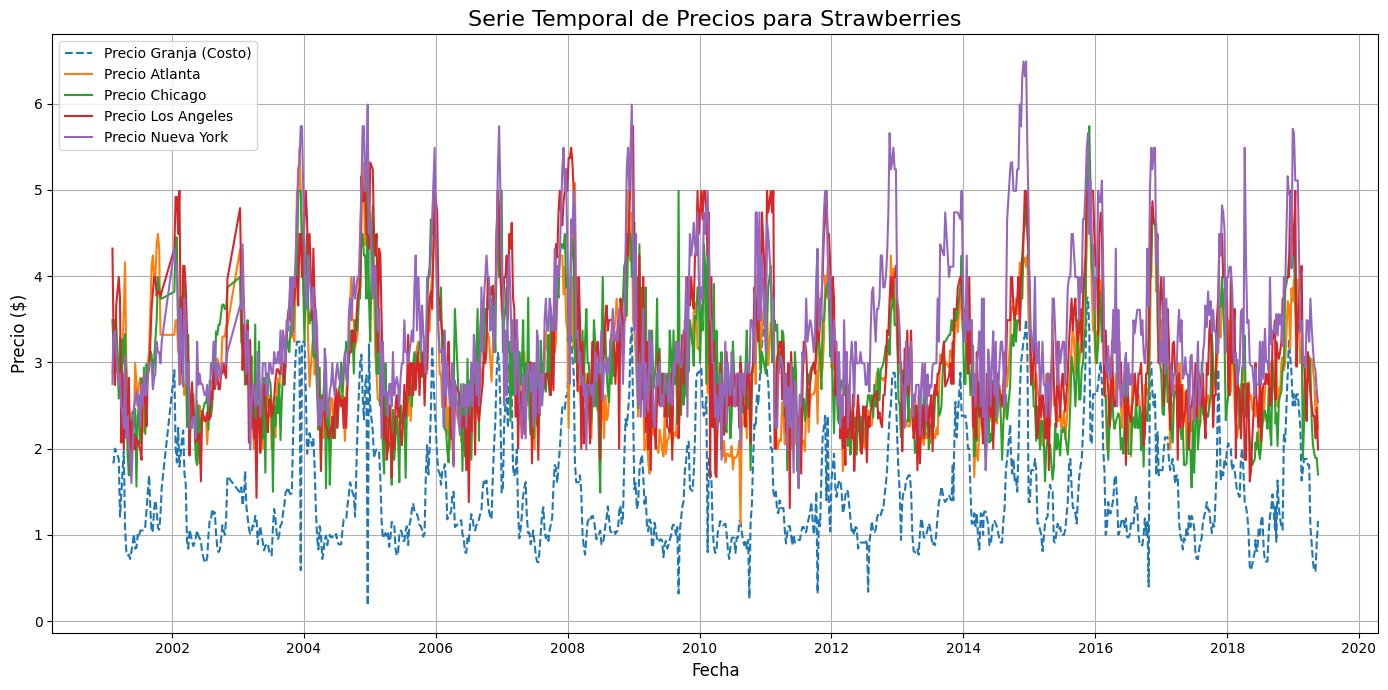

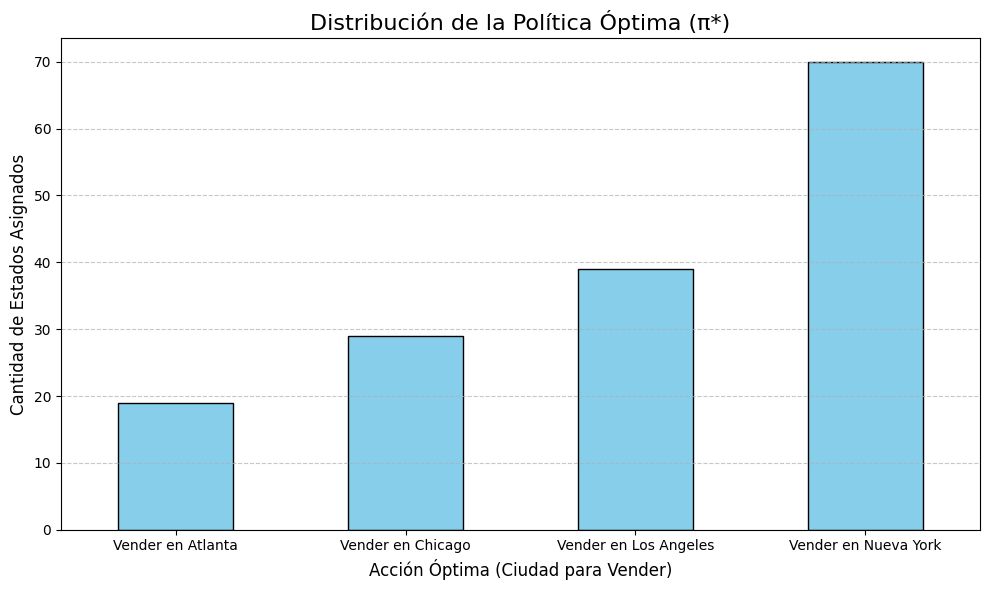

In [2]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

# --- PARÁMETROS DE EJECUCIÓN ---

# El producto que queremos analizar
PRODUCTO_A_ANALIZAR = 'Strawberries'

# Parámetros del MDP
GAMMA = 0.95  # Factor de descuento
THETA = 0.0001 # Umbral de convergencia

print(f"--- Iniciando Proceso MDP para: {PRODUCTO_A_ANALIZAR} ---")

# --- PASO 1: Cargar y Limpiar los Datos ---

print("\n--- PASO 1: Cargando y Limpiando Datos ---")
try:
    df_raw = pd.read_csv("ProductPriceIndex.csv")
except FileNotFoundError:
    print("¡ERROR! No se encontró 'ProductPriceIndex.csv'.")
    print("Por favor, súbelo al panel izquierdo de Colab y vuelve a ejecutar.")
    # Detener la ejecución si no se encuentra el archivo
    raise

# Copiamos para evitar SettingWithCopyWarning
df_clean = df_raw.copy()

# Definimos las columnas de precios
price_cols = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']

# Quitamos el símbolo '$' y convertimos a número (float)
for col in price_cols:
    df_clean[col] = df_clean[col].astype(str).str.replace('$', '', regex=False)
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Convertimos la columna 'date' a formato datetime
df_clean['date'] = pd.to_datetime(df_clean['date'])

# Filtramos solo por el producto seleccionado
df_product = df_clean[df_clean['productname'] == PRODUCTO_A_ANALIZAR].copy()

# Reemplazamos 0 por NaN (no podemos vender a 0)
df_product = df_product.replace(0, np.nan)

# Eliminamos cualquier fila (semana) que tenga un precio faltante (NaN)
rows_before = len(df_product)
df_product = df_product.dropna(subset=price_cols)
rows_after = len(df_product)
print(f"Filas eliminadas por datos faltantes/cero: {rows_before - rows_after}")

# Ordenar por fecha (¡crucial!)
df_product = df_product.sort_values(by='date').reset_index(drop=True)
print(f"Datos limpios listos para '{PRODUCTO_A_ANALIZAR}'. Total de semanas: {len(df_product)}")

# --- PASO 1.5: Gráfica (Serie de Tiempo de Precios) ---
# Esta gráfica nos ayuda a justificar el problema.
# Vemos que los precios cambian y ninguna ciudad es "siempre" la mejor.

print(f"\nGenerando gráfico 'grafico_precios_{PRODUCTO_A_ANALIZAR}.png'...")
plt.figure(figsize=(14, 7))
plt.plot(df_product['date'], df_product['farmprice'], label='Precio Granja (Costo)', linestyle='--')
plt.plot(df_product['date'], df_product['atlantaretail'], label='Precio Atlanta')
plt.plot(df_product['date'], df_product['chicagoretail'], label='Precio Chicago')
plt.plot(df_product['date'], df_product['losangelesretail'], label='Precio Los Angeles')
plt.plot(df_product['date'], df_product['newyorkretail'], label='Precio Nueva York')

plt.title(f'Serie Temporal de Precios para {PRODUCTO_A_ANALIZAR}', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio ($)', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
# Guardamos la figura para que se pueda descargar
plt.savefig(f'grafico_precios_{PRODUCTO_A_ANALIZAR}.png')
print("Gráfico de serie de tiempo guardado.")


# --- PASO 2: Discretizar y Definir Estados (S) ---

print("\n--- PASO 2: Definiendo Estados (S) ---")
cat_cols = ['farm_cat', 'atl_cat', 'chi_cat', 'la_cat', 'ny_cat']
df_states = df_product.copy()

# Discretizar usando 3 cuantiles (Bajo=0, Medio=1, Alto=2)
for i, col in enumerate(price_cols):
    cat_col_name = cat_cols[i]
    df_states[cat_col_name] = pd.qcut(df_states[col], q=3, labels=[0, 1, 2], duplicates='drop')
    df_states[cat_col_name] = df_states[cat_col_name].astype(int)

# Definir el Estado 's' como un string (ej. "0-1-2-1-0")
str_cat_cols = [col + "_str" for col in cat_cols]
for i, col in enumerate(cat_cols):
    df_states[str_cat_cols[i]] = df_states[col].astype(str)
df_states['state'] = df_states[str_cat_cols].agg('-'.join, axis=1)

STATES = sorted(df_states['state'].unique())
print(f"Total de estados (S) únicos encontrados: {len(STATES)} (de 243 teóricos)")

# --- PASO 3: Construir Recompensas (R) y Transiciones (P) ---

print("\n--- PASO 3: Construyendo Modelos R y P ---")

# --- 3a. Construir Recompensa R(s, a) ---
actions = ['atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']
reward_cols = ['R_atl', 'R_chi', 'R_la', 'R_ny']
ACTION_NAMES = {
    'R_atl': 'Vender en Atlanta',
    'R_chi': 'Vender en Chicago',
    'R_la': 'Vender en Los Angeles',
    'R_ny': 'Vender en Nueva York'
}

# Calculamos la ganancia (Recompensa) para cada acción
for i, action_col in enumerate(actions):
    df_states[reward_cols[i]] = df_states[action_col] - df_states['farmprice']

# Agrupamos por 'state' y calculamos la media de las ganancias
R_table = df_states.groupby('state')[reward_cols].mean()
R_dict = R_table.to_dict('index')
print("Tabla de Recompensas R(s, a) construida.")

# --- 3b. Construir Transición P(s' | s) ---
df_states['next_state'] = df_states['state'].shift(-1)
df_transitions = df_states.dropna(subset=['next_state'])

# Contamos transiciones (s, s')
transition_counts = df_transitions.groupby(['state', 'next_state']).size().to_frame(name='count')
# Contamos visitas totales (s)
state_counts_total = df_transitions.groupby('state').size().to_frame(name='total_s_visits')

# Calculamos P(s' | s) = count(s -> s') / total_visits(s)
P_table_full = transition_counts.join(state_counts_total, on='state')
P_table_full['prob'] = P_table_full['count'] / P_table_full['total_s_visits']

# Convertir P a un diccionario anidado para velocidad
P_dict = {}
for s in STATES:
    P_dict[s] = {} # Asegura que cada estado tenga una entrada
for _, row in P_table_full.iterrows():
    # Asegurarnos de que el estado de 'state' existe
    if row.name[0] not in P_dict:
        P_dict[row.name[0]] = {}
    P_dict[row.name[0]][row.name[1]] = row['prob']

print("Tabla de Transiciones P(s' | s) construida.")

# --- PASO 4: Resolver el MDP (Iteración de Valor) ---

print("\n--- PASO 4: Resolviendo el MDP con Iteración de Valor ---")
start_time = time.time()

# V(s) - El "Valor" de estar en un estado 's'
V = {s: 0 for s in STATES}

iteration = 0
while True:
    iteration += 1
    delta = 0
    V_new = V.copy()

    for s in STATES:
        q_sa = {}
        for a_col in reward_cols: # 'R_atl', 'R_chi', ...

            # 1. Recompensa inmediata R(s, a)
            reward = R_dict.get(s, {}).get(a_col, 0) # Usar .get para seguridad

            # 2. Valor futuro esperado: Suma[ P(s' | s, a) * V(s') ]
            expected_future_value = 0
            if s in P_dict:
                for next_s, prob in P_dict[s].items():
                    if next_s in V:
                        expected_future_value += prob * V[next_s]

            # Ecuación de Bellman
            q_sa[a_col] = reward + GAMMA * expected_future_value

        # El nuevo valor de V(s) es el MÁXIMO de Q(s,a)
        best_value = max(q_sa.values()) if q_sa else 0

        # Actualizar el valor
        V_new[s] = best_value
        delta = max(delta, abs(V[s] - V_new[s]))

    V = V_new

    if delta < THETA:
        break

end_time = time.time()
print(f"¡Convergencia alcanzada en {iteration} iteraciones!")
print(f"Tiempo total: {end_time - start_time:.2f} segundos.")

# --- PASO 5: Extraer la Política Óptima (pi*) ---

print("\n--- PASO 5: Extrayendo la Política Óptima (pi*) ---")
policy = {}

for s in STATES:
    q_sa = {}
    # Recalcular Q(s,a) usando los valores V(s) óptimos finales
    for a_col in reward_cols:
        reward = R_dict.get(s, {}).get(a_col, 0)

        expected_future_value = 0
        if s in P_dict:
            for next_s, prob in P_dict[s].items():
                 if next_s in V:
                    expected_future_value += prob * V[next_s]

        q_sa[a_col] = reward + GAMMA * expected_future_value

    # La mejor acción es la que da el MÁXIMO valor Q
    best_action_col = max(q_sa, key=q_sa.get) if q_sa else 'N/A'

    # Guardar el nombre legible
    if best_action_col != 'N/A':
      policy[s] = ACTION_NAMES[best_action_col]
    else:
      policy[s] = 'N/A'


print("\n--- ⭐️ RESULTADO: POLÍTICA ÓPTIMA (pi*) ⭐️ ---")
print("Estado (s) = (Granja-Atlanta-Chicago-LA-NY) [0=Bajo, 1=Medio, 2=Alto]")
print("------------------------------------------------------------------\n")

df_policy = pd.DataFrame(policy.items(), columns=['Estado (s)', 'Acción Óptima (a)'])

print("Primeros 15 estados:")
print(df_policy.head(15).to_string())
print("\n")

print("15 estados aleatorios:")
print(df_policy.sample(15).to_string())

# Guardar la política completa en un CSV para descargar
policy_filename = f"politica_optima_{PRODUCTO_A_ANALIZAR}.csv"
df_policy.to_csv(policy_filename, index=False)
print(f"\n¡Política completa guardada en '{policy_filename}'!")

# --- PASO 5.5: Gráfica (Distribución de la Política) ---
# Esta gráfica nos ayuda a interpretar la política.
# Muestra cuántos de los 157 estados se asignan a cada acción.

print(f"\nGenerando gráfico 'grafico_politica_{PRODUCTO_A_ANALIZAR}.png'...")
plt.figure(figsize=(10, 6))
# Contamos cuántas veces se eligió cada acción en la política
policy_counts = df_policy['Acción Óptima (a)'].value_counts().sort_index()
policy_counts.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Distribución de la Política Óptima (π*)', fontsize=16)
plt.xlabel('Acción Óptima (Ciudad para Vender)', fontsize=12)
plt.ylabel('Cantidad de Estados Asignados', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
# Guardamos la figura
plt.savefig(f'grafico_politica_{PRODUCTO_A_ANALIZAR}.png')
print("Gráfico de distribución de política guardado.")

print("\n--- FIN DEL PROCESO ---")
print("Puedes descargar los 2 archivos CSV y los 2 gráficos PNG desde el panel izquierdo de Colab.")